# Validate the plate-position correction

`1.fit_position_correction.ipynb` fits the tilt on all five plates, so it cannot show that the correction works.
Here we test the correction on data the tilt did not see.

**Question:** after the correction, can a classifier still tell which plate row a well came from?

**Design (leave one plate out).**
The screen holds out a platemap, so the held-out compounds were never in the training set.
The validation plates share the positions of the DMSO wells and differ in their compounds (three compounds on each plate, in positions that differ between plates), so we hold out one plate at a time.

1. Fit the tilt on the wells of four plates (`vpu.fit_compound_adjusted_tilt` with the controls) and correct all wells with it.
2. Train a classifier to predict the well row from the profiles of the four training plates.
3. Predict the row of the wells of the held-out plate and score it with the area under the ROC curve (AUC), where 0.5 is chance.
4. Compare three classifiers, all scored on the held-out plates:
   1. **Raw:** trained and tested on uncorrected profiles.
   2. **Corrected:** trained and tested on corrected profiles.
   3. **Shuffled:** trained on uncorrected profiles with the row labels shuffled (repeated several times), which gives the chance-level floor.

**Expectation:** the raw classifier predicts row well (high AUC), the shuffled classifier sits at chance, and the corrected classifier moves from the raw level toward the shuffled level.

The DMSO wells sit at the same positions on every plate, so a classifier can also learn the position of a well from the other plates.
The test therefore asks whether the corrected profiles still carry row information in any direction, and not only whether the correction removed the tilt.

**Output** (in this folder): `results/row_prediction_validation.csv`, `results/row_prediction_per_plate.csv`, and `figures/validation/row_prediction_validation.png`.

## Import libraries

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../../../utils")
import position_correction_utils as pcu
import validation_position_utils as vpu

## Set paths and variables

In [2]:
output_dir = pathlib.Path(".")
figure_dir = output_dir / "figures" / "validation"
figure_dir.mkdir(parents=True, exist_ok=True)
results_dir = output_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# well-level summary written by 1.fit_position_correction.ipynb
well_medians_cache = output_dir / "well_medians.parquet"
if not well_medians_cache.exists():
    raise FileNotFoundError(f"{well_medians_cache} not found. Run 1.fit_position_correction.ipynb first.")

n_shuffles = 10  # shuffled-label repetitions
min_cells = 50  # minimum cells for a well to be used

## Load the wells

In [3]:
well_medians, features = vpu.load_or_build_well_medians(well_medians_cache, ".")
wells = well_medians[well_medians["n"] >= min_cells].reset_index(drop=True)
rows, cols = pcu.well_index(wells["well"])
is_dmso = (wells["treatment"] == "DMSO").to_numpy()

print("Wells:", len(wells), "| DMSO:", int(is_dmso.sum()), "| compound:", int((~is_dmso).sum()))
print(pd.Series(rows).map(dict(enumerate(pcu.ROWS))).value_counts().sort_index().to_dict())

Wells: 300 | DMSO: 180 | compound: 120
{'B': 50, 'C': 50, 'D': 50, 'E': 50, 'F': 50, 'G': 50}


## Run the leave-one-plate-out validation

For each held-out plate, the tilt is fit on the other four plates (`vpu.fit_compound_adjusted_tilt`, with the controls), all wells are corrected with it, and the classifier is trained on the other plates.
The classifier is the one of the screen: standardize, 50 principal components, class-balanced multinomial logistic regression of the plate row (`vpu.leave_one_plate_out_row_prediction`).

In [4]:
def make_offsets(training_wells):
    """Fit the tilt on the training plates only and return its offsets of well positions."""
    fit = vpu.fit_compound_adjusted_tilt(training_wells, features, min_cells, include_controls=True)
    return lambda r, c: pcu.tilt(fit["coef"], fit["center"], r, c)


probabilities = {
    "raw": vpu.leave_one_plate_out_row_prediction(wells, features),
    "corrected": vpu.leave_one_plate_out_row_prediction(wells, features, make_offsets=make_offsets),
}
shuffled = [vpu.leave_one_plate_out_row_prediction(wells, features, shuffle_seed=s) for s in range(n_shuffles)]

## Compare held-out performance

The AUC is computed on the pooled held-out predictions of all five plates, for all wells and for the DMSO wells alone (the compound wells sit only in columns 5 to 8).
For the shuffled classifier we report the mean and standard deviation over its repetitions.
"Excess AUC removed" is how far correction moves the AUC from the raw level toward the shuffled level: `(raw - corrected) / (raw - shuffled)`.
A value of 1 means the corrected profiles are as unpredictable as shuffled labels, and 0 means no change.

In [5]:
def scores_for(subset):
    """Pooled held-out scores of the raw, corrected, and shuffled classifiers on a subset of wells."""
    raw = vpu.row_prediction_scores(rows[subset], probabilities["raw"][subset])
    corrected = vpu.row_prediction_scores(rows[subset], probabilities["corrected"][subset])
    floor = pd.DataFrame([vpu.row_prediction_scores(rows[subset], p[subset]) for p in shuffled])
    return raw, corrected, floor


records = []
for label, subset in [("all wells", np.ones(len(wells), bool)), ("DMSO wells", is_dmso)]:
    raw, corrected, floor = scores_for(subset)
    for column, name in [("macro_auc", "macro AUC over the rows"), ("row_b_auc", "row B against the rest")]:
        records.append(
            {
                "wells": label,
                "measure": name,
                "raw": raw[column],
                "corrected": corrected[column],
                "shuffled": floor[column].mean(),
                "shuffled_sd": floor[column].std(),
                "excess_auc_removed": (raw[column] - corrected[column]) / (raw[column] - floor[column].mean()),
            }
        )
results = pd.DataFrame(records)
results.round(3).to_csv(results_dir / "row_prediction_validation.csv", index=False)
print(results.round(3).to_string(index=False))

     wells                 measure   raw  corrected  shuffled  shuffled_sd  excess_auc_removed
 all wells macro AUC over the rows 0.853      0.783     0.499        0.024               0.197
 all wells  row B against the rest 0.979      0.736     0.454        0.090               0.462
DMSO wells macro AUC over the rows 0.873      0.887     0.509        0.021              -0.038
DMSO wells  row B against the rest 0.990      0.853     0.435        0.094               0.247


## Per held-out plate

The macro AUC over the rows of every plate, on its own.

 plate_number                        plate   raw  corrected  shuffled
            1 CARD-CelIns-CX7_261030160001 0.882      0.686     0.493
            2 CARD-CelIns-CX7_261031160001 0.883      0.793     0.487
            3 CARD-CelIns-CX7_261101160003 0.887      0.798     0.508
            4 CARD-CelIns-CX7_261102080001 0.837      0.846     0.515
            5 CARD-CelIns-CX7_261102150001 0.808      0.810     0.498


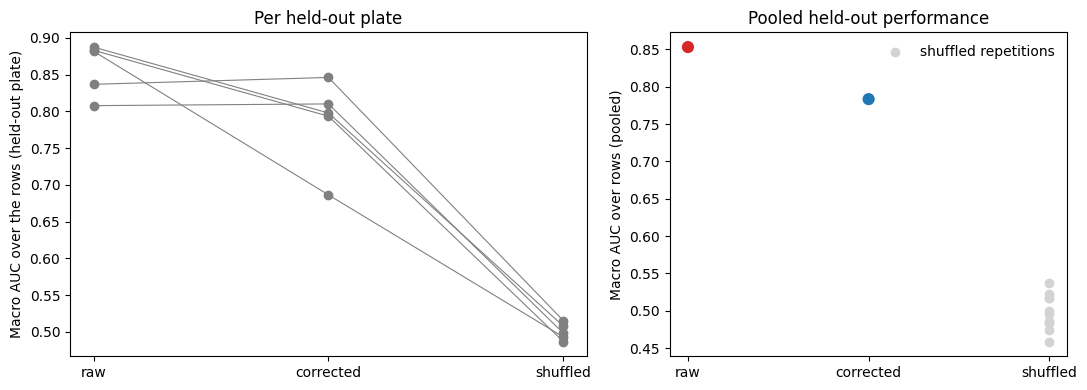

In [6]:
per_plate = []
for number, plate in enumerate(sorted(wells["plate"].unique()), start=1):
    keep = (wells["plate"] == plate).to_numpy()
    per_plate.append(
        {
            "plate_number": number,
            "plate": plate,
            "raw": vpu.row_prediction_scores(rows[keep], probabilities["raw"][keep])["macro_auc"],
            "corrected": vpu.row_prediction_scores(rows[keep], probabilities["corrected"][keep])["macro_auc"],
            "shuffled": np.mean(
                [vpu.row_prediction_scores(rows[keep], p[keep])["macro_auc"] for p in shuffled]
            ),
        }
    )
per_plate = pd.DataFrame(per_plate)
per_plate.round(3).to_csv(results_dir / "row_prediction_per_plate.csv", index=False)
print(per_plate.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})
for _, record in per_plate.iterrows():
    axes[0].plot([0, 1, 2], [record["raw"], record["corrected"], record["shuffled"]], color="grey", lw=0.8, marker="o")
axes[0].set_xticks([0, 1, 2], labels=["raw", "corrected", "shuffled"])
axes[0].set_ylabel("Macro AUC over the rows (held-out plate)")
axes[0].set_title("Per held-out plate")
all_row = results[(results["wells"] == "all wells") & (results["measure"] == "macro AUC over the rows")].iloc[0]
shuffled_macro = [vpu.row_prediction_scores(rows, p)["macro_auc"] for p in shuffled]
axes[1].scatter([2] * n_shuffles, shuffled_macro, color="lightgrey", label="shuffled repetitions")
axes[1].scatter([0, 1], [all_row["raw"], all_row["corrected"]], color=["tab:red", "tab:blue"], s=60, zorder=3)
axes[1].set_xticks([0, 1, 2], labels=["raw", "corrected", "shuffled"])
axes[1].set_ylabel("Macro AUC over rows (pooled)")
axes[1].set_title("Pooled held-out performance")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(figure_dir / "row_prediction_validation.png", dpi=120)
plt.show()

## Check that the method recovers a known tilt

We simulate the five plates on their real layouts (the real healthy DMSO, failing DMSO, and compound positions) with a known tilt (a strong row B effect), a random effect for each group of wells (the healthy DMSO, the failing DMSO, and each compound), and measurement noise.
The fit should recover the tilt without removing the group effects.
We compare the fit with one effect per group (`vpu.fit_compound_adjusted_tilt` with the controls) with a fit that has no group effects (a row plus column fit of all wells, as in the screen's `pcu.fit_tilt_map`), which counts the difference between the groups as position when the groups sit in different rows.

In [7]:
rng = np.random.default_rng(1)
n_features = 200
sim_features = [f"f{j}" for j in range(n_features)]

true_row = rng.normal(0, 1, (6, n_features)) * np.array([3.0, 0.5, 0.2, 0.4, 0.4, 0.4])[:, None]
true_col = rng.normal(0, 0.5, (10, n_features))
group_effect = {}
tables = []
for plate_name in sorted(well_medians["plate"].unique()):
    layout = well_medians[well_medians["plate"] == plate_name].reset_index(drop=True)
    sim_rows, sim_cols = pcu.well_index(layout["well"])
    simulated = true_row[sim_rows] + true_col[sim_cols] + rng.normal(0, 0.3, (len(layout), n_features))
    for i, (treatment, cell_type) in enumerate(zip(layout["treatment"], layout["cell_type"])):
        key = treatment + "|" + cell_type
        if key not in group_effect:
            group_effect[key] = rng.normal(0, 1.0, n_features)
        simulated[i] += group_effect[key]
    table = pd.DataFrame(simulated, columns=sim_features)
    table.insert(0, "n", 150)
    for column in ["cell_type", "treatment", "well"]:
        table.insert(0, column, layout[column].to_numpy())
    table.insert(0, "platemap", layout["platemap"].to_numpy())
    table.insert(0, "plate", plate_name)
    tables.append(table)
simulated_wells = pd.concat(tables, ignore_index=True)
sim_rows, sim_cols = pcu.well_index(simulated_wells["well"])
true_tilt = true_row[sim_rows] + true_col[sim_cols]

with_group_effects = vpu.fit_compound_adjusted_tilt(simulated_wells, sim_features, include_controls=True)
averaged = simulated_wells.groupby(["treatment", "cell_type", "well"])[sim_features].mean().reset_index()
avg_rows, avg_cols = pcu.well_index(averaged["well"])
coef, center = pcu.fit_tilt_map(averaged[sim_features].to_numpy(float), avg_rows, avg_cols)
without_group_effects = {"coef": coef, "center": center}


def recovery(estimated):
    """Median cosine and relative size of the estimated tilt, compared with the true tilt (both centered)."""
    tilt_estimate = pcu.tilt(estimated["coef"], estimated["center"], sim_rows, sim_cols)
    tilt_estimate = tilt_estimate - tilt_estimate.mean(axis=0)
    centered_truth = true_tilt - true_tilt.mean(axis=0)
    cosines = np.sum(tilt_estimate * centered_truth, axis=1) / (
        np.linalg.norm(tilt_estimate, axis=1) * np.linalg.norm(centered_truth, axis=1)
    )
    return float(np.median(cosines)), float(pcu.amplitude(tilt_estimate, centered_truth))


for label, estimated in [
    ("with group effects (this fit)", with_group_effects),
    ("without group effects", without_group_effects),
]:
    cosine, scale = recovery(estimated)
    print(f"{label}: median cosine to the true tilt {cosine:.2f}, estimated size / true size {scale:.2f}")

with group effects (this fit): median cosine to the true tilt 0.95, estimated size / true size 0.96
without group effects: median cosine to the true tilt 0.78, estimated size / true size 1.00


## What this does and does not show

- A drop toward the shuffled-label level means the corrected profiles carry less information about plate row, including in directions the correction did not subtract.
- It does not show that the remaining signal is the right one, or that position moves healthy and failing cells equally (`5.quantify_position_effect.ipynb` tests that).
- Shuffled labels sit at chance by construction, so being close to them is the target, and "close enough" is a judgment.
- The DMSO wells sit at the same positions on all five plates, so the held-out plate is new in its compounds and its noise, and not in the positions of its controls.
  The test is about new plates on this layout, not about new layouts.
- On the DMSO wells alone the macro AUC does not fall (0.87 before, 0.89 after), although it falls on all wells (0.85 to 0.78).
  A likely reason is that every DMSO position is the same on all plates, so the classifier can learn well-specific patterns that a row plus column tilt does not contain; we have not tested this.